# Exercise 3: CPU Inference vs Hybrid Inference on the Alveo U55C

## Objectives
In this exercise, you will:
1. Run the trained model on the CPU with ONNX Runtime
2. Run the hybrid model: the encoder on the CPU with ONNX Runtime, the pairs and the pair classifier on the Alveo U55C
3. Check that the two inferences find the same edges and the same tracks
4. Compare their time per event

## Instructions
Complete the code cells marked with `# TODO` comments. Follow the hints provided.

## Part 1: Environment Setup
Run the following cells to set up the environment (no changes needed). <br>
This exercise needs XRT, PYNQ and the card. It uses the encoder written by Exercise 1 in `work/onnx/`, and the bitstream downloaded by Exercise 2 (downloaded again if it is missing).

**Important:** the card is shared. The first cell checks that nobody is using it; loading the bitstream replaces whatever the card had.

In [1]:
# Load libraries and import packages (no changes needed)

# General imports
import os
import sys
from pathlib import Path

# Numpy
import numpy as np

# ONNX Runtime: runs ONNX models on the CPU
import onnxruntime

# PYNQ: loads a bitstream on the FPGA card and runs its kernels, from Python (it finds XRT through XILINX_XRT)
os.environ.setdefault("XILINX_XRT", "/opt/xilinx/xrt")
import pynq

# The folder of the course: the one with utils.py and hi_common.py, above the ex/ and sol/ folders
ROOT_DIR = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "utils.py").exists() and (folder / "hi_common.py").exists():
        ROOT_DIR = folder
        break
if ROOT_DIR is None:
    raise FileNotFoundError("utils.py and hi_common.py not found: open this notebook from the ex/ or sol/ folder "
                            "of the course")
sys.path.insert(0, str(ROOT_DIR))

# Local file with some useful methods (settings, events, timing, plots)
from utils import *

# Configuration and files
CONFIG = course_config(ROOT_DIR)                          # the settings of the course (in utils.py)
WORK_DIR = ROOT_DIR / "work"
FULL_MODEL = ROOT_DIR / "model" / "full_current.onnx"     # the trained model, whole
ENCODER_MODEL = WORK_DIR / "onnx" / "encoder.onnx"        # its encoder, split off in Exercise 1
BITSTREAM_FILE = download_bitstream(WORK_DIR / "fpga")    # the prebuilt bitstream (Exercise 2)
FIGURE_DIR = WORK_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
THRESHOLD = CONFIG["operating_threshold"]   # a pair is an edge when p1 is above it - DO NOT CHANGE
CARD_ADDRESS = CONFIG["fpga"]["device"]     # PCIe address of the Alveo U55C        - DO NOT CHANGE

use_course_style()
check_card_is_free(CARD_ADDRESS)
print("Environment setup correctly!")

Bitstream already downloaded: pairedges.xclbin


Xclbin UUID: 6D41F854-148C-7387-0C9B-1DC94C27A1BA
0      pairedges:pairedges_1  0xc00000      22779  (IDLE)
The card is free
Environment setup correctly!


### The Two Inferences
We run the same trained model in two ways. Both end with the same output, the **edges**: the pairs of hits with p₁ above the threshold, which the track reconstruction then joins into tracks.
- **CPU inference**: the whole model, `full_current.onnx`, with ONNX Runtime on the CPU
- **Hybrid inference**: the encoder with ONNX Runtime on the CPU; then the card builds the pairs and runs the pair classifier; then the CPU applies the softmax and the threshold

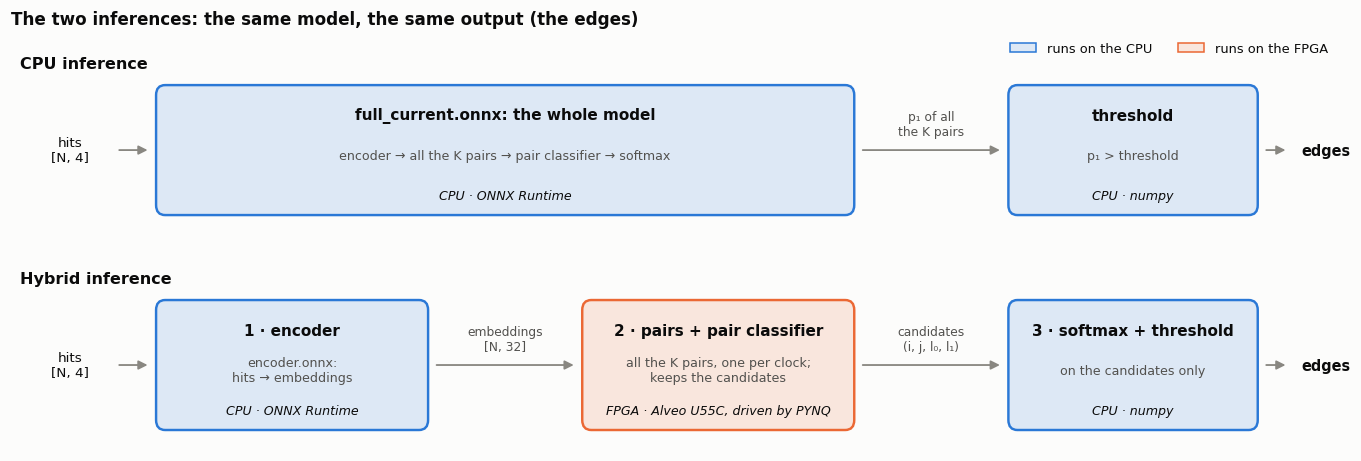

Plot saved as 'work/figures/two_inferences.png'


In [2]:
# Visualize the two inferences (no changes needed)
plot_two_inferences(save_to=FIGURE_DIR / "two_inferences.png")
print("Plot saved as 'work/figures/two_inferences.png'")

The cell below loads the 400 events of the test set, clustered as the tracking code does. `event["features"]` are the hits that the model reads, [N, 4]; the rest of each event is for the track reconstruction. We start with a median event.

In [3]:
# Load the test events, and pick a median event (no changes needed)
model_config = course_model_config(ROOT_DIR)    # the settings the GTK code reads (in utils.py)
events = load_test_events(CONFIG, model_config)
hits_per_event = np.array([len(event["features"]) for event in events])
print(f"{len(events)} events, median {np.median(hits_per_event):.0f} hits (at most {hits_per_event.max()})")

median_event = events[np.argsort(hits_per_event)[len(events) // 2]]
hits = median_event["features"]
print(f"Median event: {median_event['name']}, hits {hits.shape}")

400 events, median 51 hits (at most 136)
Median event: 61, hits (51, 4)


## Part 2: Inference on the CPU with ONNX Runtime
ONNX Runtime runs an ONNX model in two steps: create an `InferenceSession` once, then call `session.run(None, {input name: array})` for every event (`None`: return all the outputs, as a list).

The full model has two inputs: `data`, the hits [N, 4], and `pair_indices`, the pairs to score [K, 2], all the pairs (i, j) with i ≤ j (K = N(N+1)/2). Its output is the probabilities [1, K, 2]: p₀ and p₁ of every pair.

We give ONNX Runtime **one CPU thread** in both inferences: the timings are then stable, and the two inferences use the same CPU (more on this in Part 5).

In [4]:
# The settings of ONNX Runtime, for both inferences: one CPU thread (no changes needed)
session_options = onnxruntime.SessionOptions()
session_options.intra_op_num_threads = 1

### Task 2.1: Create the Session

In [5]:
# SOLUTION: create the ONNX Runtime session of the full model

full_session = onnxruntime.InferenceSession(str(FULL_MODEL), session_options, providers=["CPUExecutionProvider"])

for model_input in full_session.get_inputs():
    print(f"input  {model_input.name:13s} {model_input.shape}")
for model_output in full_session.get_outputs():
    print(f"output {model_output.name:13s} {model_output.shape}")

input  data          ['num_nodes', 4]
input  pair_indices  ['num_pairs', 2]
output output        [1, 'num_pairs', 2]


### Task 2.2: Run It on One Event

In [6]:
# SOLUTION: run the full model on the median event, and find its edges

pairs = pair_list(len(hits))
probabilities = full_session.run(None, {"data": hits, "pair_indices": pairs})[0][0]
p1 = probabilities[:, 1]
cpu_edges = np.flatnonzero(p1 > THRESHOLD)

print(f"{len(hits)} hits -> {len(pairs):,} pairs -> {len(cpu_edges)} edges")
print("The first edges (i, j):", [tuple(pair) for pair in pairs[cpu_edges[:5]].tolist()])

51 hits -> 1,326 pairs -> 381 edges
The first edges (i, j): [(0, 0), (0, 1), (0, 5), (0, 12), (0, 13)]


The same steps as a function, for any event. It returns the edges as their rows in the pair list, with their p₁.

In [7]:
# CPU inference: the whole model with ONNX Runtime (no changes needed)
def cpu_inference(hits):
    pairs = pair_list(len(hits))                                                          # [K, 2]
    probabilities = full_session.run(None, {"data": hits, "pair_indices": pairs})[0][0]   # [K, 2]
    p1 = probabilities[:, 1]
    edges = np.flatnonzero(p1 > THRESHOLD)
    return edges, p1[edges]

## Part 3: Hybrid Inference: CPU + FPGA
The hybrid inference runs the same model in three steps (the numbers of the diagram above):
1. **CPU**: ONNX Runtime runs the encoder, `encoder.onnx`: the hits [N, 4] become the embeddings [N, 32]
2. **FPGA**: the embeddings are copied to the card memory; the kernel builds every pair (i, j) and runs the pair classifier on it (the _hls4ml_ firmware of Exercise 2), one pair per clock. The card does not compute the softmax: it writes back only the **candidates**, the pairs whose logits can pass the threshold, each with its two logits l₀ and l₁
3. **CPU**: the softmax and the threshold, on the candidates only

Only the embeddings go to the card, and only the candidates come back: the K pairs never leave the card.

We drive the card from Python with **PYNQ**, the library of AMD for its FPGAs:
- `pynq.Overlay(bitstream)` loads a bitstream on the card; its kernels are attributes of the overlay
- `pynq.allocate(shape, dtype, target=...)` creates a buffer in the card memory, which on the host is a numpy array
- `buffer.sync_to_device()` copies a buffer from the host to the card (over PCIe); `buffer.sync_from_device()` copies it back
- `kernel.call(arguments)` starts the kernel with its arguments, and waits until it is done

The card keeps a pair when l₁ − l₀ is above a limit: p₁ > threshold is the same as l₁ − l₀ > log(threshold / (1 − threshold)). Its logits are integers (the logit × 2¹⁰), so the cell below writes this limit in the card's units.

In [8]:
# What the card needs to know (no changes needed)
FRACTION_BITS = PREBUILT_BITSTREAM["frac_bits"]        # the card's logits are integers: logit x 2^FRACTION_BITS
# p1 > THRESHOLD  <=>  l1 - l0 > log(THRESHOLD / (1 - THRESHOLD)), in the card's units, with a small margin
# (the exact test p1 > THRESHOLD is done on the CPU, in step 3)
CANDIDATE_THRESHOLD = int(np.floor((np.log(THRESHOLD / (1 - THRESHOLD)) - 1e-3) * 2**FRACTION_BITS))
# the bitstream declares this 32-bit argument unsigned: PYNQ wants the same 32 bits, read as an unsigned number
CANDIDATE_THRESHOLD_ARGUMENT = CANDIDATE_THRESHOLD % 2**32
print(f"The card keeps the pairs with l1 - l0 > {CANDIDATE_THRESHOLD} / 2^{FRACTION_BITS} "
      f"= {CANDIDATE_THRESHOLD / 2**FRACTION_BITS:.3f}")

The card keeps the pairs with l1 - l0 > -2251 / 2^10 = -2.198


### Task 3.1: Open the Encoder and the Card
Creating the `pynq.Overlay` **loads the bitstream on the card**.

In [9]:
# SOLUTION: create the ONNX Runtime session of the encoder, load the bitstream with PYNQ, and get its kernel

encoder_session = onnxruntime.InferenceSession(str(ENCODER_MODEL), session_options, providers=["CPUExecutionProvider"])
overlay = pynq.Overlay(str(BITSTREAM_FILE))
kernel = overlay.pairedges_1

print(f"Kernels in the bitstream: {list(overlay.ip_dict)}")
print(f"Arguments of the kernel:  {kernel.signature}")

Kernels in the bitstream: ['pairedges_1']
Arguments of the kernel:  (emb: 'void*', n_hits: 'void*', n_events: 'unsigned int', thr_raw: 'unsigned int', out_r: 'void*', n_cand: 'void*')


The kernel has six arguments, in this order:
- `emb`: the embeddings of the events, one event after the other
- `n_hits`: the number of hits of each event
- `n_events`: the number of events in this call
- `thr_raw`: the candidate threshold
- `out_r`: where the kernel writes the candidates
- `n_cand`: where the kernel writes the number of candidates of each event

The four arrays live in the card memory. The cell below allocates them in the HBM bank that the kernel reads and writes (`HBM0`), large enough for 1024 events in one call.

In [10]:
# The buffers of the four array arguments, in the card memory (no changes needed)
embeddings_buffer = pynq.allocate((65536, 32), np.float32, target=overlay.HBM0)    # emb: up to 65536 hits
n_hits_buffer = pynq.allocate(1024, np.int32, target=overlay.HBM0)                  # n_hits: up to 1024 events
candidates_buffer = pynq.allocate(1 << 22, np.uint64, target=overlay.HBM0)          # out_r: the candidates
n_candidates_buffer = pynq.allocate(1024, np.int32, target=overlay.HBM0)            # n_cand
buffers = [embeddings_buffer, n_hits_buffer, candidates_buffer, n_candidates_buffer]
print(f"{sum(buffer.nbytes for buffer in buffers) / 1e6:.0f} MB allocated in the HBM of the card")

42 MB allocated in the HBM of the card


Now the three steps of the hybrid inference, on the same median event.

### Task 3.2: Step 1, the Encoder (CPU)

In [11]:
# SOLUTION: run the encoder on the hits of the median event

embeddings = encoder_session.run(None, {"data": hits})[0][0]

print(f"hits {hits.shape} -> embeddings {embeddings.shape}: {embeddings.nbytes:,} bytes to send to the card")

hits (51, 4) -> embeddings (51, 32): 6,528 bytes to send to the card


### Task 3.3: Step 2, the Pairs and the Pair Classifier (FPGA)
Three parts: copy the inputs to the card, run the kernel, copy the outputs back. Only the first elements of each buffer are copied: a slice of a buffer, `buffer[:size]`, is a buffer too.

In [12]:
# SOLUTION: run step 2 on the card: copy the inputs, run the kernel on one event, copy the candidates back

n = len(embeddings)

# 2a. The inputs: write them into the buffers, then copy them to the card
embeddings_buffer[:n] = embeddings
n_hits_buffer[0] = n
embeddings_buffer[:n].sync_to_device()
n_hits_buffer[:1].sync_to_device()

# 2b. Run the kernel on one event, and wait until it is done
kernel.call(embeddings_buffer, n_hits_buffer, 1, CANDIDATE_THRESHOLD_ARGUMENT,
            candidates_buffer, n_candidates_buffer)

# 2c. The outputs: copy back the number of candidates, then the candidates
n_candidates_buffer[:1].sync_from_device()
n_candidates = int(n_candidates_buffer[0])
candidates_buffer[:n_candidates].sync_from_device()
candidates = np.array(candidates_buffer[:n_candidates])

print(f"{len(pair_list(n)):,} pairs computed on the card -> {n_candidates} candidates copied back "
      f"({candidates.nbytes:,} bytes)")

1,326 pairs computed on the card -> 381 candidates copied back (3,048 bytes)


Each candidate is one 64-bit word with four 16-bit fields: the hits i and j of the pair, and its two logits as integers (logit × 2¹⁰). `unpack_candidates` (in `utils.py`) takes them apart, and turns each (i, j) into the row of the pair in the pair list, as the CPU inference gives it.

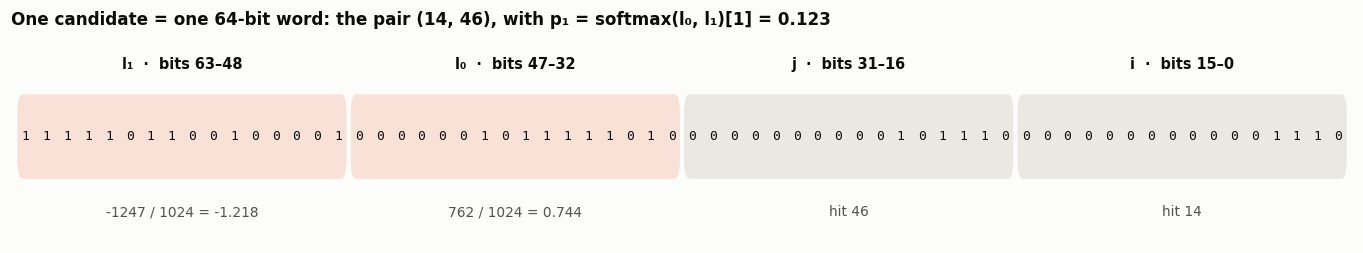

Plot saved as 'work/figures/candidate.png'
The first candidates: rows [ 0  1  5 12], l0 [0.4267578  0.8222656  1.4765625  0.76953125], l1 [-0.546875   -0.45507812 -0.69140625 -0.6699219 ]


In [13]:
# Look at one candidate, and unpack all of them (no changes needed)
plot_candidate(candidates[n_candidates // 2], FRACTION_BITS, save_to=FIGURE_DIR / "candidate.png")
print("Plot saved as 'work/figures/candidate.png'")

rows, logit0, logit1 = unpack_candidates(candidates, [n_candidates], [n], FRACTION_BITS)
print(f"The first candidates: rows {rows[:4]}, l0 {logit0[:4]}, l1 {logit1[:4]}")

### Task 3.4: Step 3, the Softmax and the Threshold (CPU)

In [14]:
# SOLUTION: compute p₁ of the candidates, and keep those above the threshold

p1 = 1 / (1 + np.exp(logit0 - logit1))
hybrid_edges = rows[p1 > THRESHOLD]

print(f"{len(rows)} candidates -> {len(hybrid_edges)} edges")
in_both = len(np.intersect1d(cpu_edges, hybrid_edges))
print(f"Compared with the CPU inference: {in_both} edges in common, {len(cpu_edges) - in_both} only on the CPU, "
      f"{len(hybrid_edges) - in_both} only in the hybrid")

381 candidates -> 381 edges
Compared with the CPU inference: 381 edges in common, 0 only on the CPU, 0 only in the hybrid


The three steps together, as a function, for any event:

In [15]:
# Hybrid inference: the encoder on the CPU, the pairs and the pair classifier on the card (no changes needed)
def hybrid_inference(hits):
    n = len(hits)
    # Step 1, CPU: the encoder with ONNX Runtime
    embeddings = encoder_session.run(None, {"data": hits})[0][0]                                   # [N, 32]
    # Step 2, FPGA: the inputs to the card, the kernel, the candidates back
    embeddings_buffer[:n] = embeddings
    n_hits_buffer[0] = n
    embeddings_buffer[:n].sync_to_device()
    n_hits_buffer[:1].sync_to_device()
    kernel.call(embeddings_buffer, n_hits_buffer, 1, CANDIDATE_THRESHOLD_ARGUMENT,
                candidates_buffer, n_candidates_buffer)
    n_candidates_buffer[:1].sync_from_device()
    n_candidates = int(n_candidates_buffer[0])
    candidates_buffer[:n_candidates].sync_from_device()
    rows, logit0, logit1 = unpack_candidates(candidates_buffer[:n_candidates], [n_candidates], [n], FRACTION_BITS)
    # Step 3, CPU: the softmax and the threshold, on the candidates only
    p1 = 1 / (1 + np.exp(logit0 - logit1))
    keep = p1 > THRESHOLD
    return rows[keep], p1[keep]

## Part 4: The Same Results?
The pair classifier on the card computes in fixed point (Exercise 2): p₁ moves by up to about 10⁻³, so a pair whose p₁ is right at the threshold can change side. Do the two inferences find the same edges, and the same tracks?

### Task 4.1: Run the Two Inferences on All the Events

In [16]:
# SOLUTION: run the two inferences on every event

cpu_results = [cpu_inference(event["features"]) for event in events]
hybrid_results = [hybrid_inference(event["features"]) for event in events]

print(f"Edges of the CPU inference:    {sum(len(edges) for edges, _ in cpu_results):,}")
print(f"Edges of the hybrid inference: {sum(len(edges) for edges, _ in hybrid_results):,}")

Edges of the CPU inference:    165,986
Edges of the hybrid inference: 165,908


The cell below finds the pairs that are an edge for only one of the two inferences, and their p₁ on the CPU. Then it reconstructs the tracks from the edges of each inference, with the track reconstruction of the GTK code, and compares them with the true tracks.

174 edges differ, all within 4.0e-04 of the threshold


Tracks of the cpu    inference: 3,955 true positives, 421 false positives, 874 missed
Tracks of the hybrid inference: 3,954 true positives, 422 false positives, 875 missed


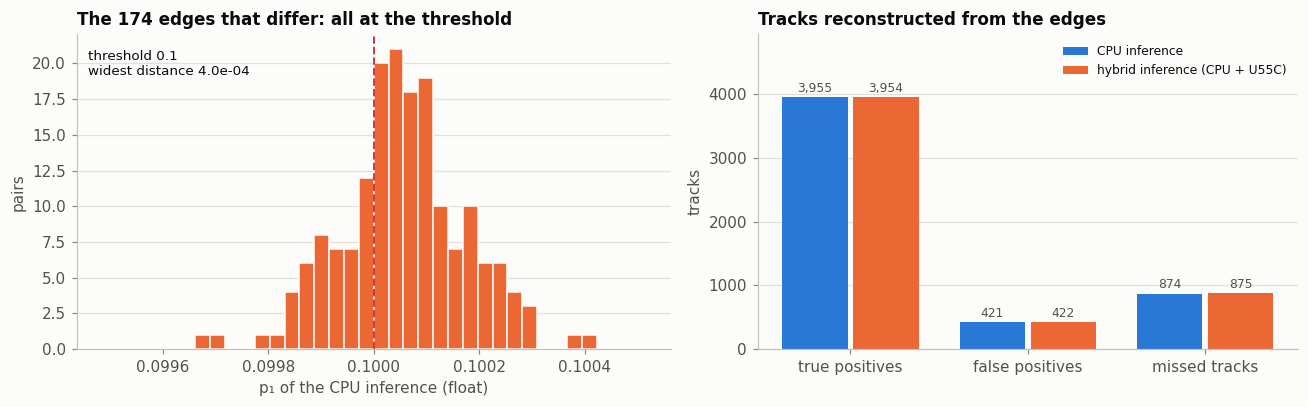

Plot saved as 'work/figures/agreement.png'


In [17]:
# Compare the edges and the tracks of the two inferences (no changes needed)
differing_p1 = []         # the CPU's p1 of the pairs that are an edge for only one of the two
for event, (cpu_edges_of_event, _), (hybrid_edges_of_event, _) in zip(events, cpu_results, hybrid_results):
    differing_rows = np.setxor1d(cpu_edges_of_event, hybrid_edges_of_event)
    if len(differing_rows) > 0:
        event_hits = event["features"]
        probabilities = full_session.run(None, {"data": event_hits, "pair_indices": pair_list(len(event_hits))})[0][0]
        differing_p1.extend(probabilities[differing_rows, 1])
differing_p1 = np.array(differing_p1)
print(f"{len(differing_p1)} edges differ, all within {np.abs(differing_p1 - THRESHOLD).max():.1e} of the threshold")

tracks = {"cpu": count_tracks(CONFIG, events, cpu_results), "hybrid": count_tracks(CONFIG, events, hybrid_results)}
for name, (true_positives, false_positives, missed) in tracks.items():
    print(f"Tracks of the {name:6s} inference: {true_positives:,} true positives, {false_positives:,} false positives, "
          f"{missed:,} missed")

plot_agreement(differing_p1, THRESHOLD, tracks, save_to=FIGURE_DIR / "agreement.png")
print("Plot saved as 'work/figures/agreement.png'")

The few edges that differ are all pairs whose p₁ sits right at the threshold, where the fixed-point rounding can push them to the other side; and the tracks of the two inferences agree to within one or two.

## Part 5: Which Is Faster?
`time_per_event(inference, events)` (in `utils.py`) runs an inference several times on every event, after a few warm-up events, and returns the median time of each event in µs. Both inferences run ONNX Runtime on one CPU thread.

### Task 5.1: Measure the Two Inferences

In [18]:
# SOLUTION: measure the time per event of the two inferences

cpu_us = time_per_event(cpu_inference, events)
hybrid_us = time_per_event(hybrid_inference, events)

print(f"CPU inference:    median {np.median(cpu_us):6.1f} µs per event")
print(f"Hybrid inference: median {np.median(hybrid_us):6.1f} µs per event")
print(f"Speed-up of the hybrid: {np.median(cpu_us) / np.median(hybrid_us):.2f}×")

CPU inference:    median  353.5 µs per event
Hybrid inference: median  332.2 µs per event
Speed-up of the hybrid: 1.06×


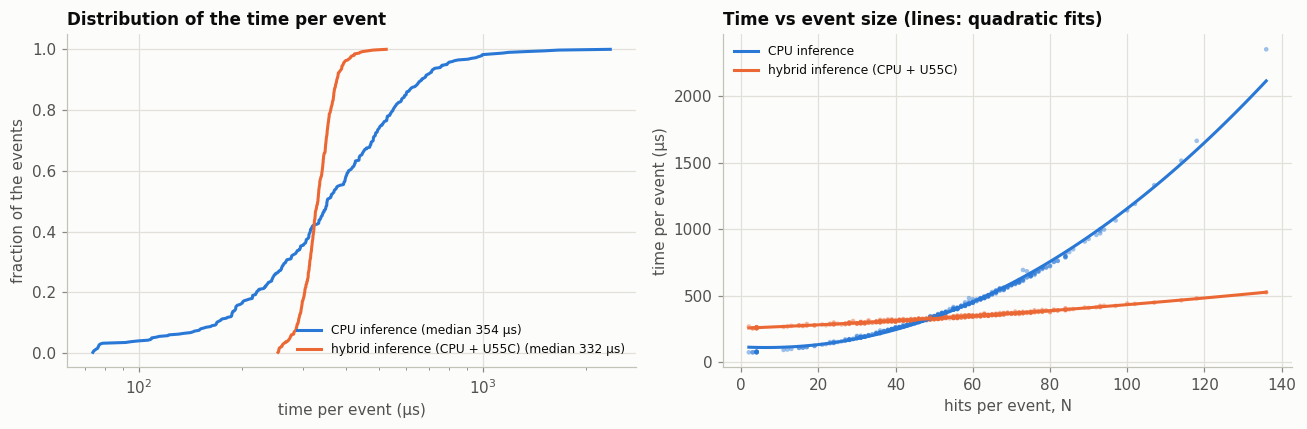

Plot saved as 'work/figures/latency.png'


In [19]:
# Visualize the time per event (no changes needed)
plot_latency({"cpu": cpu_us, "hybrid": hybrid_us}, hits_per_event, save_to=FIGURE_DIR / "latency.png")
print("Plot saved as 'work/figures/latency.png'")

With one event per call the hybrid is only a little faster than the CPU. The card itself is fast: for a median event the kernel runs in about 15 µs. But every call costs about 140 µs more: the four copies over PCIe and the start of the kernel, each through the Python layers of PYNQ. So the hybrid wins on the large events (above about 50 hits), where the work of the CPU grows like N², and loses on the small ones, where this fixed cost is most of the time.

**A note on threads.** ONNX Runtime can also split each operation over the 4 cores of this machine. On a quiet machine this makes the CPU inference about 20% faster (the hybrid hardly changes: its encoder is small), faster than the hybrid with one event per call, but still much slower than the hybrid with batching (Part 6). But the timings then vary a lot from run to run, because the cores are shared with Jupyter and the other processes: this is why we compare one thread with one thread.

## Part 6: Several Events per Card Call (Batching)
The fixed cost of a card call is paid once per call. If we send B events in one call, each event pays only 1/B of it. The encoder still runs event by event on the CPU; then the embeddings of all the events go to the card together, and the kernel processes the events one after the other. The catch: each event waits until its batch is complete, so batching suits offline processing better than a strict per-event latency budget.

### Task 6.1: The Hybrid Inference of a Batch

In [20]:
# SOLUTION: write steps 1 and 2a for a batch of events, and run the kernel once for all of them

def hybrid_inference_batch(batch):
    n_hits = [len(event["features"]) for event in batch]
    # Step 1, CPU: the encoder, event by event
    embeddings = [encoder_session.run(None, {"data": event["features"]})[0][0] for event in batch]
    # Step 2, FPGA: the inputs of all the events to the card, one kernel call, the candidates back
    embeddings_buffer[:sum(n_hits)] = np.concatenate(embeddings)
    n_hits_buffer[:len(batch)] = n_hits
    embeddings_buffer[:sum(n_hits)].sync_to_device()
    n_hits_buffer[:len(batch)].sync_to_device()
    kernel.call(embeddings_buffer, n_hits_buffer, len(batch), CANDIDATE_THRESHOLD_ARGUMENT,
                candidates_buffer, n_candidates_buffer)
    n_candidates_buffer[:len(batch)].sync_from_device()
    n_candidates = np.array(n_candidates_buffer[:len(batch)])
    # the candidates of each event start at a multiple of 8 (a new 512-bit word of the card memory)
    size = sum(int(np.ceil(count / 8)) * 8 for count in n_candidates)
    candidates_buffer[:size].sync_from_device()
    rows, logit0, logit1 = unpack_candidates(candidates_buffer[:size], n_candidates, n_hits, FRACTION_BITS)
    # Step 3, CPU: the softmax and the threshold on all the candidates, then the edges of each event
    p1 = 1 / (1 + np.exp(logit0 - logit1))
    keep = p1 > THRESHOLD
    ends = np.cumsum(n_candidates)[:-1]           # where the candidates of each event end
    return [(event_rows[event_keep], event_p1[event_keep]) for event_rows, event_p1, event_keep
            in zip(np.split(rows, ends), np.split(p1, ends), np.split(keep, ends))]

# Check: one call for 32 events gives the same edges as 32 calls of one event
for (batch_edges, _), (single_edges, _) in zip(hybrid_inference_batch(events[:32]), hybrid_results[:32]):
    assert np.array_equal(batch_edges, single_edges)
print("The edges of one call for 32 events == the edges of 32 calls")

The edges of one call for 32 events == the edges of 32 calls


  1 per call:  383.2 µs per event


  2 per call:  276.3 µs per event


  4 per call:  214.4 µs per event


  8 per call:  178.8 µs per event
 16 per call:  154.6 µs per event


 32 per call:  146.1 µs per event


 64 per call:  144.0 µs per event


128 per call:  140.4 µs per event


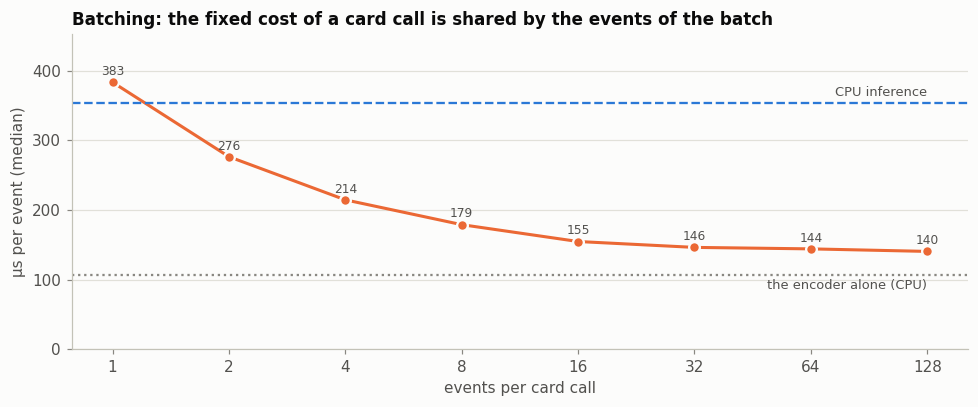

Plot saved as 'work/figures/batching.png'


In [21]:
# Measure the time per event with 1 to 128 events per card call (no changes needed)
batched_us = {}
for batch_size in (1, 2, 4, 8, 16, 32, 64, 128):
    batched_us[batch_size] = time_per_event_in_batches(hybrid_inference_batch, events, batch_size)
    print(f"{batch_size:3d} per call: {batched_us[batch_size]:6.1f} µs per event")

encoder_us = time_per_event(lambda hits: encoder_session.run(None, {"data": hits}), events)   # the encoder alone
plot_batching(batched_us, np.median(cpu_us), np.median(encoder_us), save_to=FIGURE_DIR / "batching.png")
print("Plot saved as 'work/figures/batching.png'")

With a few tens of events per call the fixed cost of the card is almost gone, and the hybrid becomes more than twice as fast as the CPU. What remains is the encoder on the CPU (the dotted line), and the Python work of each event. (With one event, `hybrid_inference_batch` is a little slower than `hybrid_inference`: it does more bookkeeping.)

## Summary

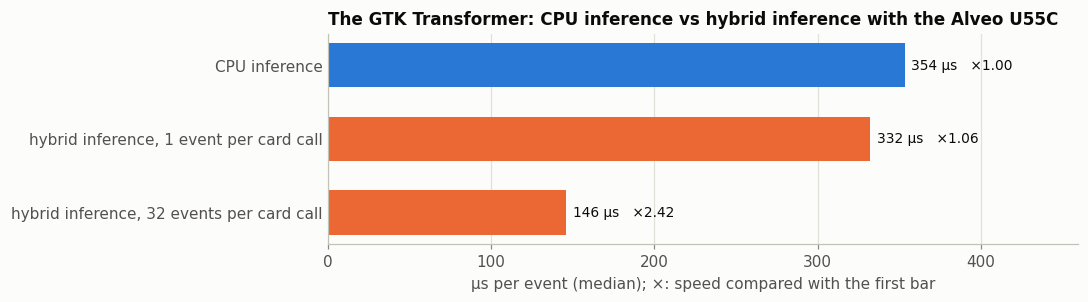

Plot saved as 'work/figures/summary.png'


Card released


In [22]:
# The final comparison, and release the card (no changes needed)
plot_summary([("CPU inference", np.median(cpu_us), "cpu"),
              ("hybrid inference, 1 event per card call", np.median(hybrid_us), "hybrid"),
              ("hybrid inference, 32 events per card call", batched_us[32], "hybrid")],
             save_to=FIGURE_DIR / "summary.png")
print("Plot saved as 'work/figures/summary.png'")

for buffer in buffers:
    buffer.freebuffer()
overlay.free()
print("Card released")

**What you have done.** You took a Transformer that _hls4ml_ cannot convert as a whole (Exercise 0), split it where it goes from hits to pairs (Exercise 1), turned its pair classifier into fixed-point firmware with _hls4ml_ (Exercise 2), and ran it on the Alveo U55C, with PYNQ, inside a kernel that builds the pairs on the chip (this exercise).

The hybrid inference finds the same tracks as the CPU inference (to within one or two). It is faster on the large events, and, with several events per card call, more than twice as fast on average. Two things limit it now. The fixed cost of each card call: a host driver written in C++ on top of XRT makes it about 3 times smaller than PYNQ does (in the project this course comes from, such a driver makes the hybrid about 1.9× faster than the CPU already with one event per call). And the encoder on the CPU, the next part to move to the FPGA.